# 01 — Exploring Next-Day SPY Volatility

For my project, I predict at the end of day t whether the next SPY trading day will have high 20-day rolling volatility. One row is one trading day. Today's three predictors describe day t; `target` describes day t+1, and `target_date` shows which trading day that is.

I kept the setup from Weeks 4–8. This notebook downloads only 2020–2025, so the 2026 holdout stays unused. Run the cells in order with an internet connection.

In [1]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt

# Find the shared code from the project folder or the notebooks folder.
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
elif (project_root / "ANLY530_SPY_Volatility_Project").is_dir():
    project_root = project_root / "ANLY530_SPY_Volatility_Project"
sys.path.insert(0, str(project_root))

from src.data_utils import download_spy, create_features, create_target, FEATURES, EVALUATION_YEARS

## Load the public prices

I use adjusted daily SPY closing prices from [Yahoo Finance through yfinance](https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html). The end date is exclusive, so `2026-01-01` does not include any 2026 observations.

In [2]:
prices = download_spy()
print(f"Downloaded trading days: {len(prices):,}")
print(f"Price dates: {prices.index.min().date()} to {prices.index.max().date()}")
print(f"Missing closing prices: {prices['Close'].isna().sum()}")
assert prices.index.max() < pd.Timestamp("2026-01-01")

Downloaded trading days: 1,508
Price dates: 2020-01-02 to 2025-12-31
Missing closing prices: 0


## Keep the same predictors and target

Daily return is today's adjusted price change divided by the previous trading day's adjusted close. The 5-day mean includes today's return, and 20-day volatility is the sample standard deviation of the latest 20 returns. These values are decimals, not percentages or annualized volatility.

I set the cutoff at the 75th percentile of valid volatility values from 2020–2023. The target is 1 if the next trading day's volatility is strictly above that fixed cutoff, and 0 otherwise. The shift moves tomorrow's class onto today's row; it does not move tomorrow's information into the predictors.

In [3]:
feature_data = create_features(prices)
prepared_data, cutoff = create_target(feature_data)
print(f"Fixed 2020–2023 volatility cutoff: {cutoff:.4%}")

# Show the rolling-window gaps and the unknown final outcome before removal.
columns = FEATURES + ["target", "target_date"]
print("Missing values before removing incomplete rows:")
print(prepared_data[columns].isna().sum().to_string())

data = prepared_data.dropna(subset=columns).copy()
data["target"] = data["target"].astype(int)
print(f"\nRows removed: {len(prepared_data) - len(data)}")
print(f"Complete observations: {len(data):,}")
print("Missing values after removal:")
print(data[columns].isna().sum().to_string())

Fixed 2020–2023 volatility cutoff: 1.3905%
Missing values before removing incomplete rows:
daily_return          1
average_return_5d     5
volatility_20d       20
target               21
target_date           1

Rows removed: 21
Complete observations: 1,487
Missing values after removal:
daily_return         0
average_return_5d    0
volatility_20d       0
target               0
target_date          0


The initial gaps come from needing enough past returns for the rolling calculations. The last row has no next-day outcome in this download. I remove those incomplete rows using the same rule as the earlier notebooks.

In [4]:
# Only these three columns will be used as predictors.
print("Predictors:", FEATURES)
print(f"Feature dates: {data.index.min().date()} to {data.index.max().date()}")
print(f"Target dates: {data['target_date'].min().date()} to {data['target_date'].max().date()}")
display(data[FEATURES + ["target_date", "target"]].head())

assert (data["target_date"] > data.index).all()
assert data["target_date"].max() < pd.Timestamp("2026-01-01")

Predictors: ['daily_return', 'average_return_5d', 'volatility_20d']
Feature dates: 2020-01-31 to 2025-12-30
Target dates: 2020-02-03 to 2025-12-31


,daily_return,average_return_5d,volatility_20d,target_date,target
Date,,,,,
2020-01-31,-0.018158,-0.004258,0.007553,2020-02-03,0
2020-02-03,0.007428,0.000434,0.007554,2020-02-04,0
2020-02-04,0.015241,0.001386,0.008236,2020-02-05,0
2020-02-05,0.011548,0.003861,0.008519,2020-02-06,0
2020-02-06,0.003365,0.003885,0.008485,2020-02-07,0


## Check the target distribution

The first table describes all complete 2020–2025 observations. Labels before 2024 use a cutoff defined later, so this is a retrospective description of the training history. It is not evidence of an earlier live forecast.

I also show the two development evaluation years separately. This helps explain why one year can have a high overall accuracy but still miss the uncommon high-volatility days.

In [5]:
counts = data["target"].value_counts().reindex([0, 1], fill_value=0)
distribution = pd.DataFrame({
    "Count": counts,
    "Percentage": (counts / len(data) * 100).round(2)
})
distribution.index = ["Normal Volatility", "High Volatility"]
display(distribution)

period_rows = []
for year in EVALUATION_YEARS:
    period = data[data["target_date"].dt.year == year]
    period_rows.append({
        "Evaluation Year": year,
        "Observations": len(period),
        "High-volatility days": int(period["target"].sum()),
        "High-volatility percentage": round(period["target"].mean() * 100, 2)
    })
period_distribution = pd.DataFrame(period_rows)
display(period_distribution)

,Count,Percentage
Normal Volatility,1208,81.24
High Volatility,279,18.76


,Evaluation Year,Observations,High-volatility days,High-volatility percentage
0,2024,252,4,1.59
1,2025,250,28,11.20


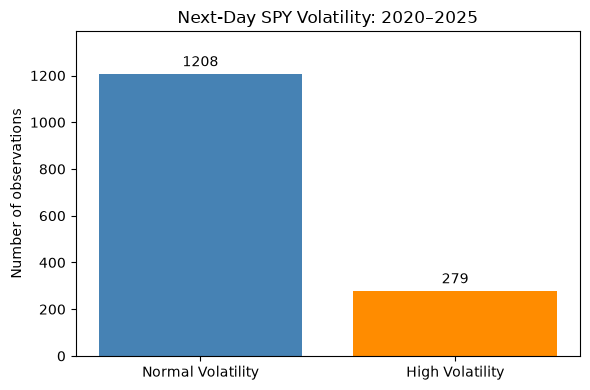

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(distribution.index, distribution["Count"], color=["steelblue", "darkorange"])
ax.bar_label(bars, padding=3)
ax.set_title("Next-Day SPY Volatility: 2020–2025")
ax.set_ylabel("Number of observations")
ax.set_ylim(0, distribution["Count"].max() * 1.15)
plt.tight_layout()
plt.show()

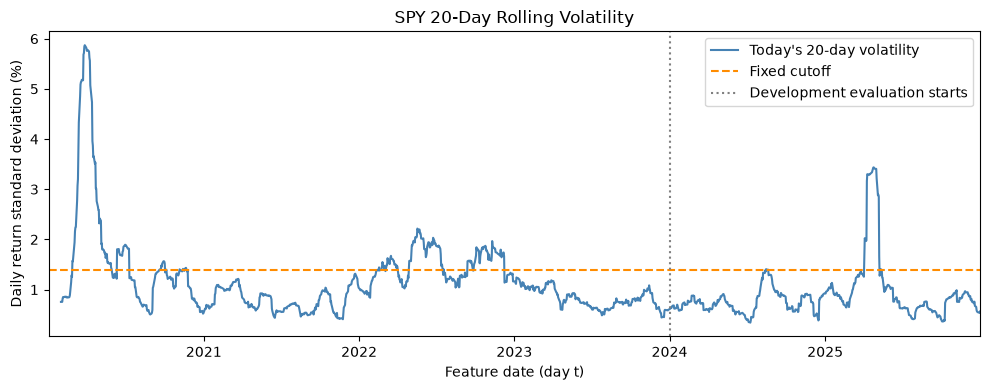

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(feature_data.index, feature_data["volatility_20d"] * 100,
        color="steelblue", label="Today's 20-day volatility")
ax.axhline(cutoff * 100, color="darkorange", linestyle="--", label="Fixed cutoff")
ax.axvline(pd.Timestamp("2024-01-01"), color="gray", linestyle=":",
           label="Development evaluation starts")
ax.set_title("SPY 20-Day Rolling Volatility")
ax.set_xlabel("Feature date (day t)")
ax.set_xlim(prices.index.min(), prices.index.max())
ax.set_ylabel("Daily return standard deviation (%)")
ax.legend()
plt.tight_layout()
plt.show()

The line plot shows today's volatility. The target on each row comes from the following trading day's value, so the line and target are deliberately one day apart. I show the historical cutoff across the chart for reference; it was only available after 2023.

Today's and tomorrow's 20-day windows share 19 returns. This makes volatility persistence part of the prediction problem, rather than a direct forecast of a sudden market shock.

## Check overlap between the predictors

I use only the first training period for this correlation check, as in Weeks 6 and 7. Daily return is also part of the 5-day average, so some overlap is expected. Correlation describes association; it does not show causation or establish independence within each target class.

In [8]:
first_train = data[data["target_date"] < "2024-01-01"]
correlations = first_train[FEATURES].corr()
display(correlations.round(2))

print(f"High-volatility outcomes make up {data['target'].mean():.2%} of complete observations.")
print("I will keep the same three predictors and compare models on 2024 and 2025.")
print("The 2026 holdout has not been downloaded or evaluated.")

,daily_return,average_return_5d,volatility_20d
daily_return,1.00,0.42,0.02
average_return_5d,0.42,1.00,-0.03
volatility_20d,0.02,-0.03,1.00


High-volatility outcomes make up 18.76% of complete observations.
I will keep the same three predictors and compare models on 2024 and 2025.
The 2026 holdout has not been downloaded or evaluated.
